# Sales Forecasting - AIML Capstone 3
Fresh Analytics wants to understand and forecast demand for items across six restaurants (2019-2021).
"Sales" in this notebook means **revenue = price x item_count** unless stated otherwise (item counts are shown where relevant).
Figures are saved to `figures/` for the submission screenshots.

In [1]:
import os, warnings, time, copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
pd.set_option("display.width",160); pd.set_option("display.max_columns",30)
os.makedirs("figures",exist_ok=True)
T0=time.time()
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png",dpi=110); plt.show()
def rmse(a,b): return float(np.sqrt(mean_squared_error(a,b)))

## 1. Preliminary analysis
### 1a. Import the datasets

In [2]:
sales=pd.read_csv("data/sales.csv",parse_dates=["date"])
items=pd.read_csv("data/items.csv")
rest=pd.read_csv("data/resturants.csv")   # file name is spelled this way in the course data
for n,d in [("sales",sales),("items",items),("restaurants",rest)]:
    print(n,d.shape); display(d.head(3))

sales (109600, 4)


,date,item_id,price,item_count
0,2019-01-01,3,29.22,2.0
1,2019-01-01,4,26.42,22.0
2,2019-01-01,12,4.87,7.0


items (100, 5)


,id,store_id,name,kcal,cost
0,1,4,Chocolate Cake,554,6.71
1,2,4,Breaded Fish with Vegetables Meal,772,15.09
2,3,1,Sweet Fruity Cake,931,29.22


restaurants (6, 2)


,id,name
0,1,Bob's Diner
1,2,Beachfront Bar
2,3,Sweet Shack


### 1b. Shape, structure and outliers

In [3]:
for n,d in [("sales",sales),("items",items),("restaurants",rest)]:
    print("=====",n); d.info(); print("missing:",int(d.isna().sum().sum()),"| duplicates:",int(d.duplicated().sum()))
display(sales.describe()); display(items.describe())
print("Date range:",sales.date.min().date(),"->",sales.date.max().date(),"| unique days:",sales.date.nunique())
print("Share of rows with item_count == 0: %.1f%%"%(100*(sales.item_count==0).mean()))
chk=sales.merge(items,left_on="item_id",right_on="id")
print("Rows where sales price != items cost:",int((chk.price!=chk.cost).sum()))

===== sales
<class 'pandas.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   date        109600 non-null  datetime64[us]
 1   item_id     109600 non-null  int64         
 2   price       109600 non-null  float64       
 3   item_count  109600 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1)
memory usage: 3.3 MB
missing: 0 | duplicates: 0
===== items
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        100 non-null    int64  
 1   store_id  100 non-null    int64  
 2   name      100 non-null    str    
 3   kcal      100 non-null    int64  
 4   cost      100 non-null    float64
dtypes: float64(1), int64(3), str(1)
memory usage: 4.0 KB
missing: 0 | duplicates: 0
===== restaurants
<class 'pandas.Data

,date,item_id,price,item_count
count,109600,109600.000000,109600.000000,109600.000000
mean,2020-07-01 12:00:00,50.500000,11.763700,6.339297
min,2019-01-01 00:00:00,1.000000,1.390000,0.000000
25%,2019-10-01 18:00:00,25.750000,5.280000,0.000000
50%,2020-07-01 12:00:00,50.500000,7.625000,0.000000
75%,2021-04-01 06:00:00,75.250000,18.790000,0.000000
max,2021-12-31 00:00:00,100.000000,53.980000,570.000000
std,NaN,28.866202,8.946225,30.003728


,id,store_id,kcal,cost
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,3.520000,536.730000,11.763700
std,29.011492,1.708446,202.212852,8.991254
min,1.000000,1.000000,78.000000,1.390000
25%,25.750000,2.000000,406.250000,5.280000
50%,50.500000,4.000000,572.500000,7.625000
75%,75.250000,5.000000,638.250000,18.790000
max,100.000000,6.000000,1023.000000,53.980000


Date range: 2019-01-01 -> 2021-12-31 | unique days: 1096
Share of rows with item_count == 0: 78.6%
Rows where sales price != items cost: 0


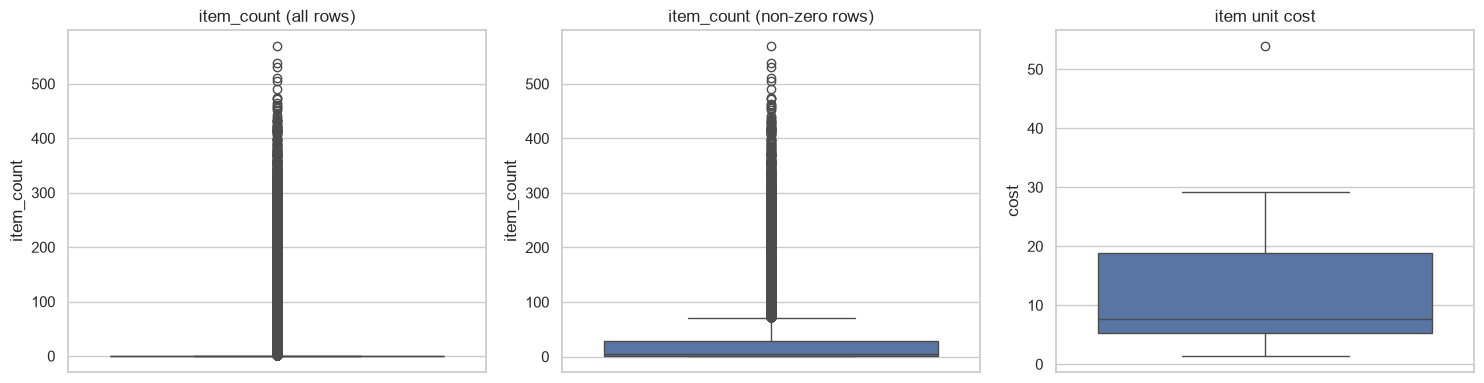

Non-zero item_count IQR outliers (> Q3+1.5 IQR = 71): 2595 of 23484
Duplicate item names across stores: 6


In [4]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
sns.boxplot(y=sales.item_count,ax=ax[0]); ax[0].set_title("item_count (all rows)")
sns.boxplot(y=sales.loc[sales.item_count>0,"item_count"],ax=ax[1]); ax[1].set_title("item_count (non-zero rows)")
sns.boxplot(y=items.cost,ax=ax[2]); ax[2].set_title("item unit cost")
save("01_outliers")
nz=sales.loc[sales.item_count>0,"item_count"]; q1,q3=nz.quantile([.25,.75]); iqr=q3-q1
print("Non-zero item_count IQR outliers (> Q3+1.5 IQR = %.0f): %d of %d"%(q3+1.5*iqr,(nz>q3+1.5*iqr).sum(),len(nz)))
print("Duplicate item names across stores:",items.name.duplicated().sum())

**Interpretation.** All three files load cleanly: sales has 109,600 rows (100 items x 1,096 days, 2019-01-01 to 2021-12-31), items 100 rows, restaurants 6 rows. There are no missing values and no duplicate rows. About 79% of sales rows have `item_count = 0` (item not sold that day), and the non-zero counts are strongly right-skewed (2,595 of 23,484 non-zero rows exceed the IQR fence of 71, maximum 570). These are genuine high-demand days of popular items, not entry errors, so no rows were removed. The sales price equals the item cost for every row, so prices are constant per item. Six item names repeat across stores, so the merge uses item id, not name.

### 1c. Merge into one dataset

In [5]:
df=(sales.merge(items.rename(columns={"id":"item_id","name":"item_name","cost":"item_cost"}),on="item_id",how="left")
         .merge(rest.rename(columns={"id":"store_id","name":"store_name"}),on="store_id",how="left"))
df["revenue"]=df.price*df.item_count
df=df[["date","item_id","price","item_count","item_name","kcal","store_id","store_name","revenue"]]
print(df.shape,"| nulls after merge:",int(df.isna().sum().sum())); df.head()

(109600, 9) | nulls after merge: 0


,date,item_id,price,item_count,item_name,kcal,store_id,store_name,revenue
0,2019-01-01,3,29.22,2.0,Sweet Fruity Cake,931,1,Bob's Diner,58.44
1,2019-01-01,4,26.42,22.0,Amazing Steak Dinner with Rolls,763,1,Bob's Diner,581.24
2,2019-01-01,12,4.87,7.0,Fantastic Sweet Cola,478,1,Bob's Diner,34.09
3,2019-01-01,13,4.18,12.0,Sweet Frozen Soft Drink,490,1,Bob's Diner,50.16
4,2019-01-01,16,3.21,136.0,Frozen Milky Smoothy,284,1,Bob's Diner,436.56


## 2. Exploratory data analysis
### 2a. Examine overall sales

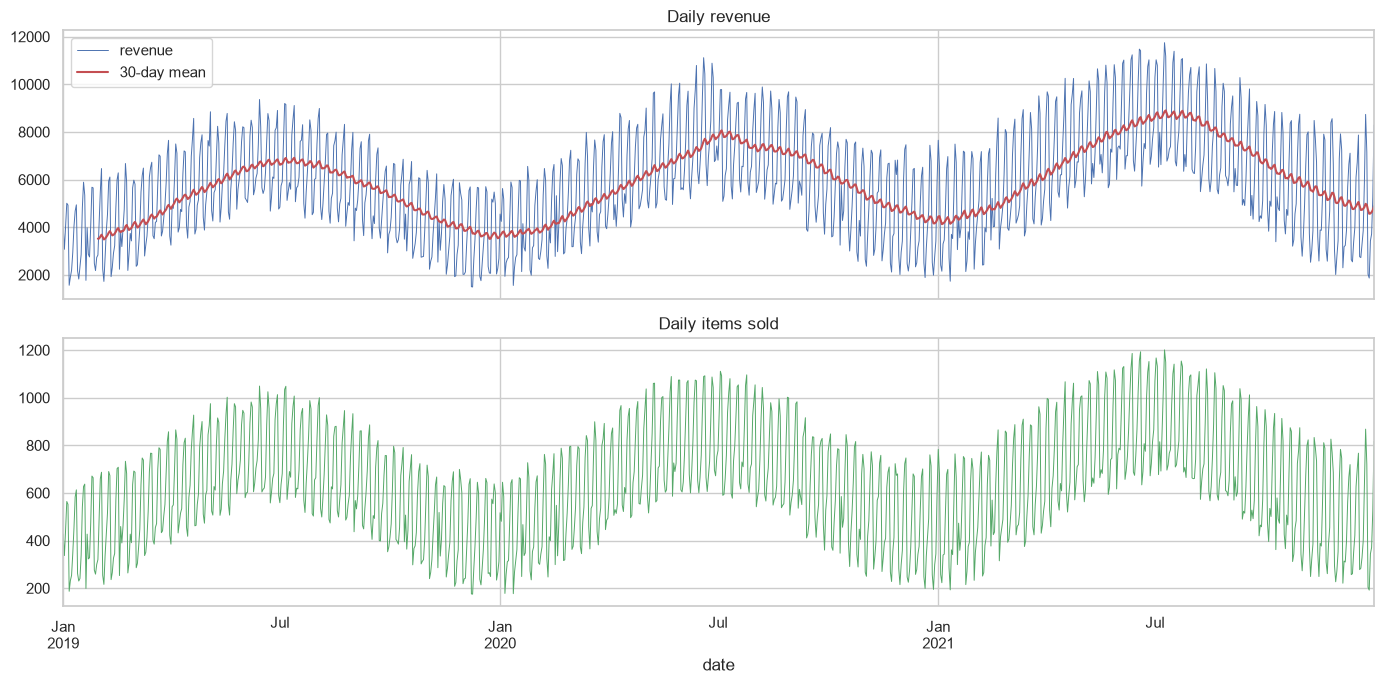

,revenue,items
year,,
2019,1871762.31,214237.0
2020,2133680.78,232581.0
2021,2398295.36,247969.0


In [6]:
daily=df.groupby("date").agg(revenue=("revenue","sum"),items=("item_count","sum"))
fig,ax=plt.subplots(2,1,figsize=(14,7),sharex=True)
daily.revenue.plot(ax=ax[0],lw=.7); daily.revenue.rolling(30).mean().plot(ax=ax[0],color="r",label="30-day mean"); ax[0].legend(); ax[0].set_title("Daily revenue")
daily["items"].plot(ax=ax[1],lw=.7,color="g"); ax[1].set_title("Daily items sold")
save("02_overall_sales")
yr=df.assign(year=df.date.dt.year).groupby("year").agg(revenue=("revenue","sum"),items=("item_count","sum")); display(yr)

**Interpretation.** Revenue grows year on year (about 1.87M in 2019, 2.13M in 2020 and 2.40M in 2021, roughly +14% then +12%), with a strong repeating annual cycle (peaks in mid-year, troughs around the turn of the year) and a short weekly cycle visible in the noisy daily series. Items sold grow more slowly than revenue (214k, 233k, 248k), so part of the growth is a shift towards higher-priced items.

### 2b. Sales by day of week

dow
Monday       4133.0
Tuesday      4679.0
Wednesday    5176.0
Thursday     6838.0
Friday       8009.0
Saturday     8017.0
Sunday       4040.0
Name: revenue, dtype: float64

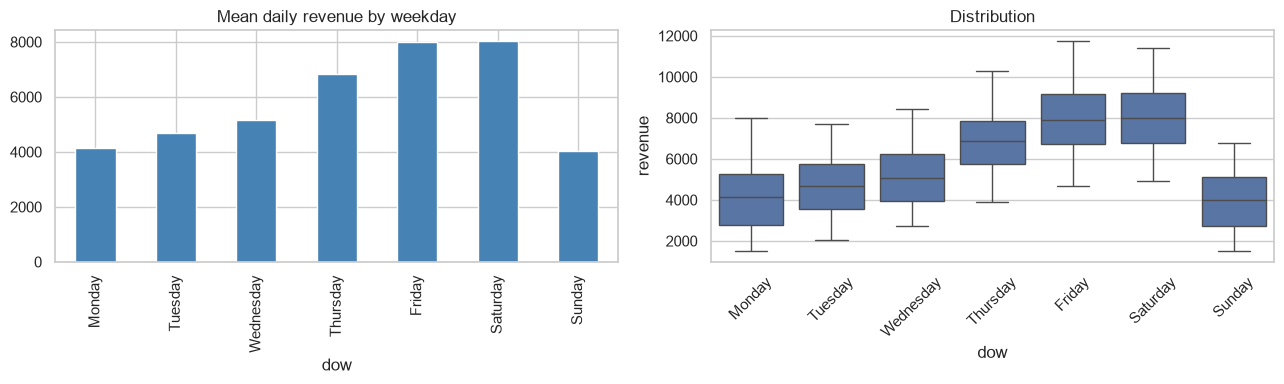

In [7]:
d2=daily.reset_index(); d2["dow"]=d2.date.dt.day_name(); order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow=d2.groupby("dow").revenue.mean().reindex(order); display(dow.round(0))
fig,ax=plt.subplots(1,2,figsize=(13,4)); dow.plot.bar(ax=ax[0],color="steelblue"); ax[0].set_title("Mean daily revenue by weekday")
sns.boxplot(data=d2,x="dow",y="revenue",order=order,ax=ax[1]); ax[1].tick_params(axis="x",rotation=45); ax[1].set_title("Distribution")
save("03_day_of_week")

### 2c. Monthly trends

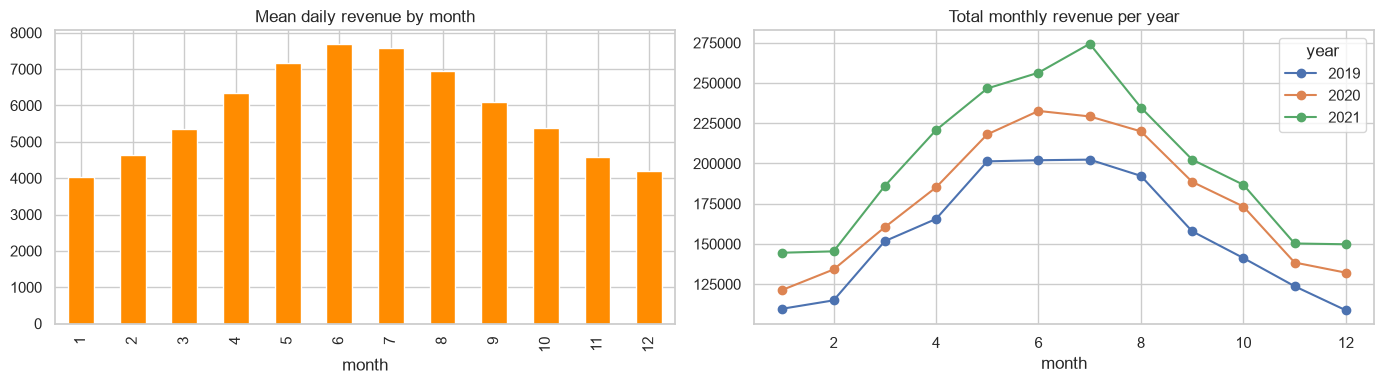

Best month: 6 | weakest: 1


In [8]:
d2["month"]=d2.date.dt.month; d2["year"]=d2.date.dt.year; d2["quarter"]=d2.date.dt.quarter
mon=d2.groupby("month").revenue.mean()
fig,ax=plt.subplots(1,2,figsize=(14,4)); mon.plot.bar(ax=ax[0],color="darkorange"); ax[0].set_title("Mean daily revenue by month")
d2.pivot_table(index="month",columns="year",values="revenue",aggfunc="sum").plot(ax=ax[1],marker="o"); ax[1].set_title("Total monthly revenue per year")
save("04_monthly"); print("Best month:",mon.idxmax(),"| weakest:",mon.idxmin())

**Interpretation.** Monthly averages show a clear seasonal hump: June is the strongest month and January the weakest. Revenue rises from January to a plateau in May-August and falls again through autumn. The three yearly curves have the same shape, only at higher levels each year.

### 2d. Quarterly distribution averaged over the years

quarter,1,2,3,4
year,,,,
2019,376465.0,568911.0,552585.0,373802.0
2020,416037.0,635915.0,637833.0,443896.0
2021,476023.0,723811.0,711573.0,486888.0


quarter
1    422841.0
2    642879.0
3    633997.0
4    434862.0
dtype: float64

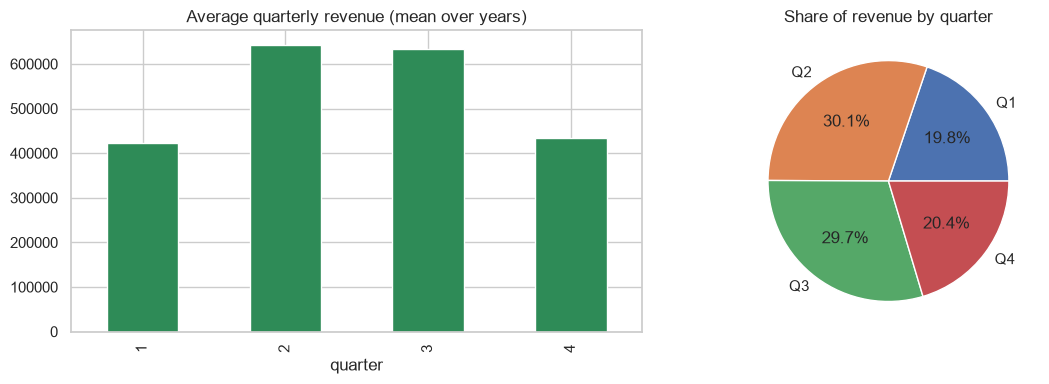

In [9]:
q=d2.groupby(["year","quarter"]).revenue.sum().unstack(); display(q.round(0)); qa=q.mean(); display(qa.round(0))
fig,ax=plt.subplots(1,2,figsize=(12,4)); qa.plot.bar(ax=ax[0],color="seagreen"); ax[0].set_title("Average quarterly revenue (mean over years)")
ax[1].pie(qa,labels=[f"Q{i}" for i in qa.index],autopct="%1.1f%%"); ax[1].set_title("Share of revenue by quarter")
save("05_quarterly")

**Interpretation.** Quarterly sales are strongly seasonal and consistent across all three years: Q2 (about 643k on average) and Q3 (about 634k) are roughly 50% higher than Q1 (about 423k) and Q4 (about 435k). Q2 and Q3 together account for about 60% of annual revenue.

### 2e. Restaurant performance (most sales; by year, month, day)

,revenue,items
store_name,,
Bob's Diner,6337276.0,687527.0
Fou Cher,27885.0,1106.0
Corner Cafe,16551.0,1310.0
Surfs Up,15651.0,1803.0
Beachfront Bar,3796.0,1305.0
Sweet Shack,2578.0,1736.0


Top restaurant by revenue: Bob's Diner


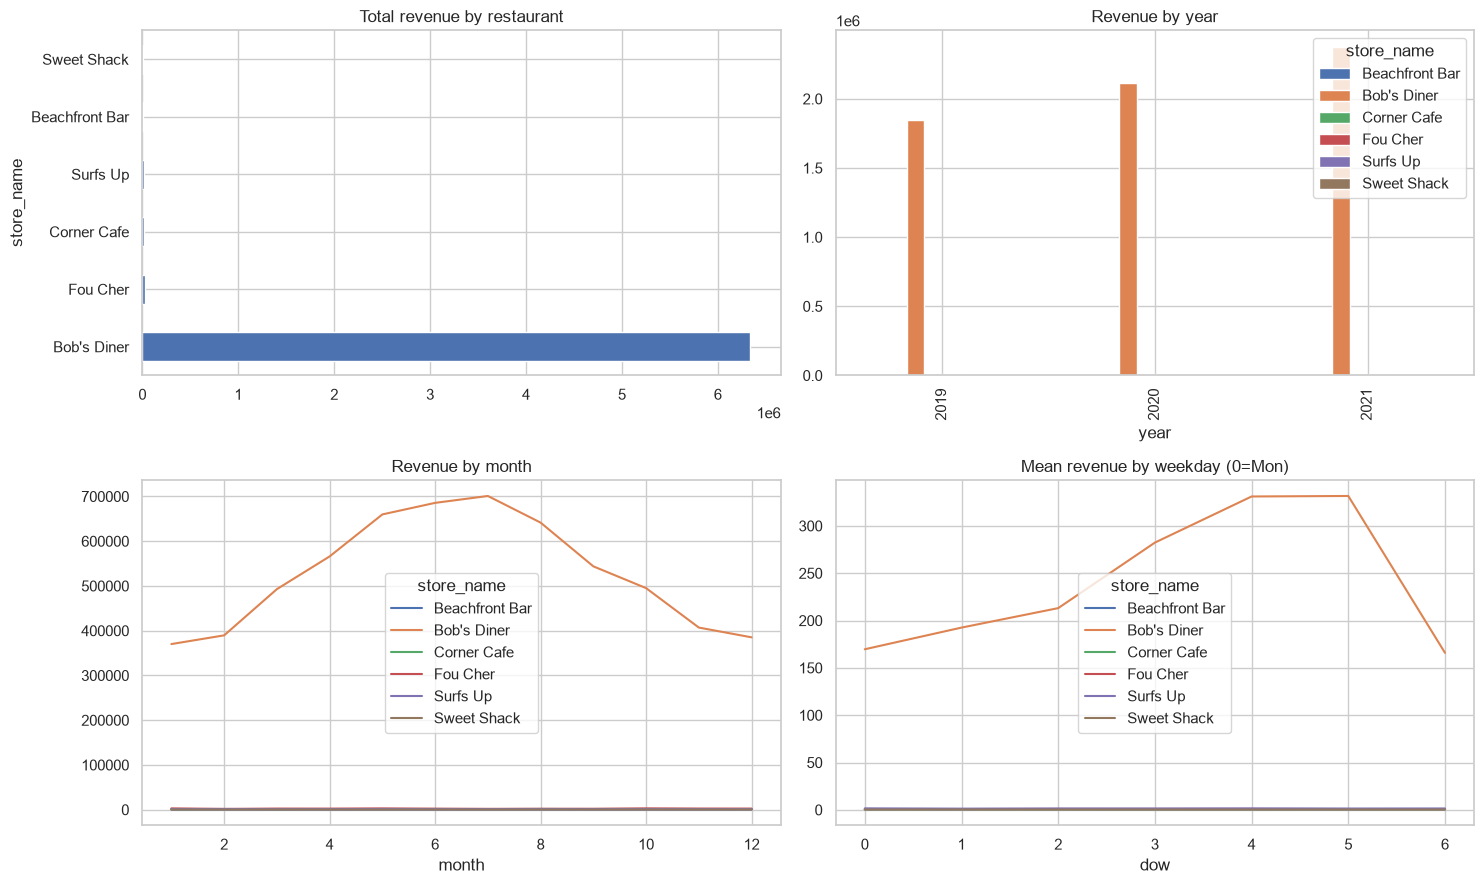

In [10]:
rs=df.groupby("store_name").agg(revenue=("revenue","sum"),items=("item_count","sum")).sort_values("revenue",ascending=False); display(rs.round(0))
print("Top restaurant by revenue:",rs.index[0])
dd=df.assign(year=df.date.dt.year,month=df.date.dt.month,dow=df.date.dt.dayofweek)
fig,ax=plt.subplots(2,2,figsize=(15,9))
rs.revenue.plot.barh(ax=ax[0,0]); ax[0,0].set_title("Total revenue by restaurant")
dd.pivot_table(index="year",columns="store_name",values="revenue",aggfunc="sum").plot.bar(ax=ax[0,1]); ax[0,1].set_title("Revenue by year")
dd.pivot_table(index="month",columns="store_name",values="revenue",aggfunc="sum").plot(ax=ax[1,0]); ax[1,0].set_title("Revenue by month")
dd.pivot_table(index="dow",columns="store_name",values="revenue",aggfunc="mean").plot(ax=ax[1,1]); ax[1,1].set_title("Mean revenue by weekday (0=Mon)")
save("06_restaurants")

**Interpretation.** Bob's Diner dominates: about 6.34M of the roughly 6.40M total revenue (99%+). The other five restaurants have only tiny sales (about 1 to 2 units a day), which is a notable feature of this dataset. The charts by year, month and weekday are therefore essentially the shape of Bob's Diner; the other stores are near zero on the same scale.

### 2f. Most popular items and where they are sold

Top 10 items (item x store) by units sold


,item_name,store_name,item_count
91,Strawberry Smoothy,Bob's Diner,236337.0
47,Frozen Milky Smoothy,Bob's Diner,102990.0
9,Amazing pork lunch,Bob's Diner,61043.0
68,Mutton Dinner,Bob's Diner,52772.0
71,Orange Juice,Bob's Diner,43874.0
22,Blue Ribbon Beef Entree,Bob's Diner,42774.0
4,Amazing Steak Dinner with Rolls,Bob's Diner,34439.0
94,Sweet Frozen Soft Drink,Bob's Diner,27490.0
89,Sea Bass with Vegetables Dinner,Bob's Diner,23839.0
96,Sweet Lamb Cake,Bob's Diner,18764.0


Most popular item at each store


,store_name,item_name,item_count
1,Beachfront Bar,Fantastic Milky Smoothy,1147.0
25,Bob's Diner,Strawberry Smoothy,236337.0
40,Corner Cafe,Frozen Milky Smoothy,273.0
57,Fou Cher,Blue Ribbon Fruity Vegi Lunch,298.0
85,Surfs Up,Awesome Soft Drink,997.0
92,Sweet Shack,Awesome Smoothy,1692.0


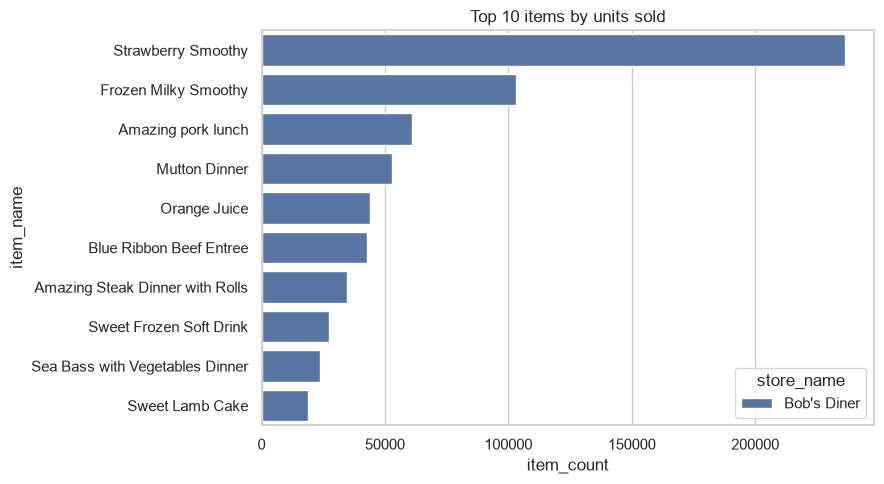

In [11]:
pop=df.groupby(["item_name","store_name"]).item_count.sum().reset_index().sort_values("item_count",ascending=False)
print("Top 10 items (item x store) by units sold"); display(pop.head(10))
ps=df.groupby(["store_name","item_name"]).item_count.sum().reset_index()
top_store=ps.loc[ps.groupby("store_name").item_count.idxmax()]; print("Most popular item at each store"); display(top_store)
plt.figure(figsize=(9,5)); sns.barplot(data=pop.head(10),y="item_name",x="item_count",hue="store_name",dodge=False); plt.title("Top 10 items by units sold"); save("07_popular_items")

**Interpretation.** The ten most popular item-store pairs are all at Bob's Diner, led by Strawberry Smoothy (about 236k units), then Frozen Milky Smoothy and Amazing pork lunch. The most popular item at each other store is Fantastic Milky Smoothy (Beachfront Bar), Frozen Milky Smoothy (Corner Cafe), Blue Ribbon Fruity Vegi Lunch (Fou Cher), Awesome Soft Drink (Surfs Up) and Awesome Smoothy (Sweet Shack), but at only a few hundred to a couple of thousand units over three years.

### 2g. Is the highest-volume store also making the most money per day?

,units_per_day,revenue_per_day
store_name,,
Bob's Diner,627.3,5782.2
Surfs Up,1.6,14.3
Sweet Shack,1.6,2.4
Corner Cafe,1.2,15.1
Beachfront Bar,1.2,3.5
Fou Cher,1.0,25.4


Highest volume: Bob's Diner | highest revenue per day: Bob's Diner


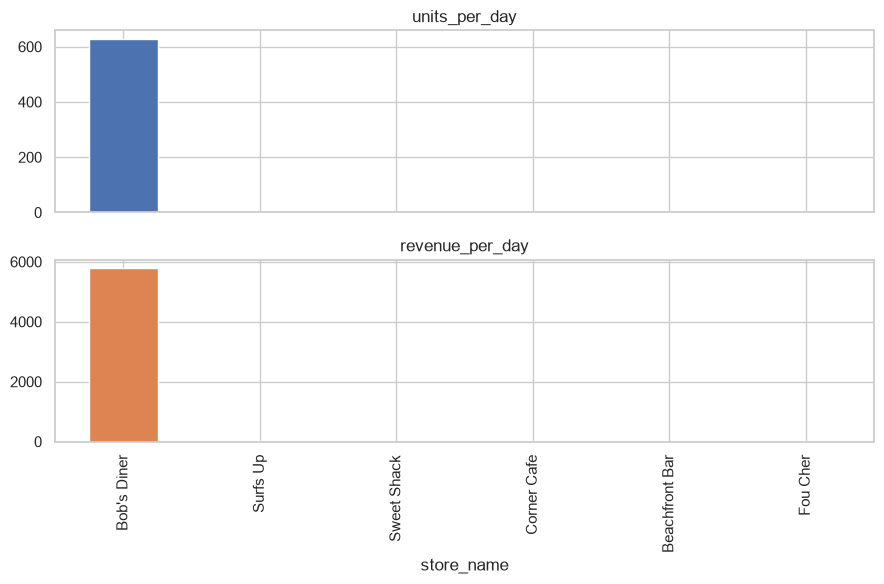

In [12]:
sd=df.groupby(["store_name","date"]).agg(rev=("revenue","sum"),units=("item_count","sum")).reset_index()
g=sd.groupby("store_name").agg(units_per_day=("units","mean"),revenue_per_day=("rev","mean")).sort_values("units_per_day",ascending=False); display(g.round(1))
print("Highest volume:",g.units_per_day.idxmax(),"| highest revenue per day:",g.revenue_per_day.idxmax())
g.plot.bar(subplots=True,figsize=(9,6),legend=False); save("08_volume_vs_money")

**Interpretation.** Yes. Bob's Diner has both the highest volume (about 627 units a day) and the highest revenue per day (about 5,782 per day); the next best store makes only about 25 per day. For the smaller stores, volume and revenue do not rank identically (for example Surfs Up sells more units than Fou Cher but earns less per day because its items are cheaper).

### 2h. Most expensive item at each restaurant and its calories

In [13]:
ix=items.merge(rest.rename(columns={"id":"store_id","name":"store_name"}),on="store_id")
exp=ix.loc[ix.groupby("store_name").cost.idxmax(),["store_name","name","cost","kcal"]].rename(columns={"name":"item_name"}); display(exp)

,store_name,item_name,cost,kcal
61,Beachfront Bar,Sweet Vegi Soft Drink,5.70,538
2,Bob's Diner,Sweet Fruity Cake,29.22,931
49,Corner Cafe,Pike Lunch,26.37,653
79,Fou Cher,Blue Ribbon Fruity Vegi Lunch,53.98,881
26,Surfs Up,Steak Meal,26.21,607
76,Sweet Shack,Blue Ribbon Frozen Milky Cake,7.70,636


## 3. Forecasting using machine learning
### 3a. Feature engineering (daily total revenue)

In [14]:
ts=daily[["revenue"]].copy()
def feats(idx):
    return pd.DataFrame({"dayofweek":idx.dayofweek,"month":idx.month,"year":idx.year,"quarter":idx.quarter,"dayofmonth":idx.day,
                         "dayofyear":idx.dayofyear,"weekofyear":idx.isocalendar().week.astype(int).values,"is_weekend":(idx.dayofweek>=5).astype(int)},index=idx)
X=feats(ts.index); y=ts.revenue
split=ts.index.max()-pd.DateOffset(months=6)
tr=ts.index<=split; te=~tr
print("Train:",ts.index[tr].min().date(),"->",ts.index[tr].max().date(),int(tr.sum()),"days | Test (last 6 months):",ts.index[te].min().date(),"->",ts.index[te].max().date(),int(te.sum()),"days")
X.head()

Train: 2019-01-01 -> 2021-06-30 912 days | Test (last 6 months): 2021-07-01 -> 2021-12-31 184 days


,dayofweek,month,year,quarter,dayofmonth,dayofyear,weekofyear,is_weekend
date,,,,,,,,
2019-01-01,1,1,2019,1,1,1,1,0
2019-01-02,2,1,2019,1,2,2,1,0
2019-01-03,3,1,2019,1,3,3,1,0
2019-01-04,4,1,2019,1,4,4,1,0
2019-01-05,5,1,2019,1,5,5,1,1


### 3b. Linear Regression, Random Forest, XGBoost (RMSE on the last six months)
A seasonal-naive baseline (same weekday, 364 days earlier) is added only as a sanity reference.

,Model,RMSE,MAPE %
0,Random Forest,826.85,11.08
1,XGBoost,894.98,14.56
2,Seasonal naive (364d),967.80,11.81
3,Linear Regression,2234.61,40.57


Best model: Random Forest


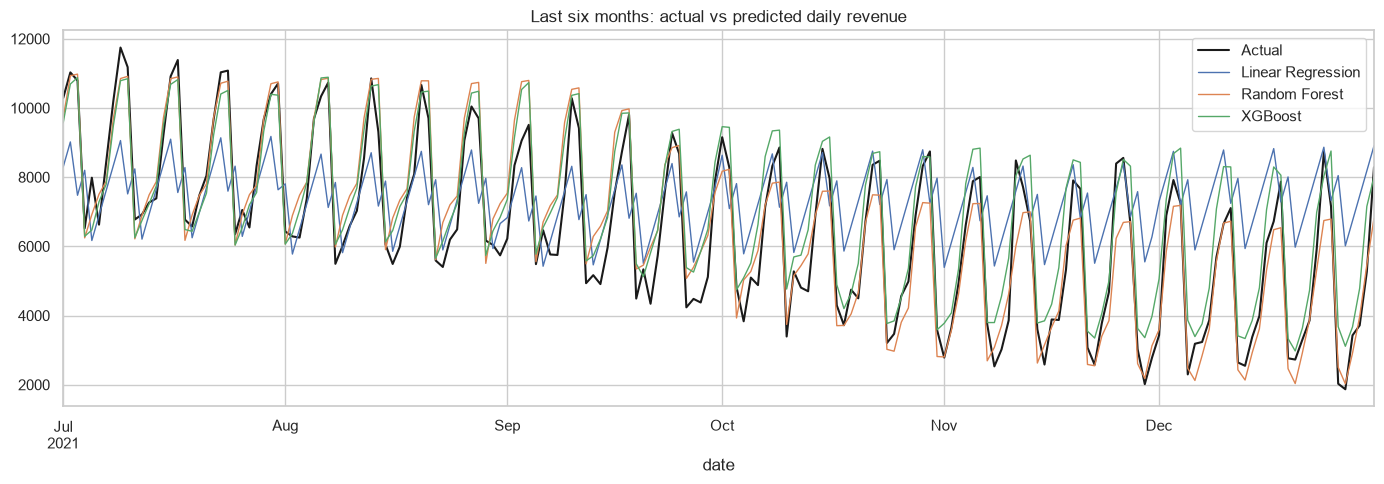

In [15]:
models={"Linear Regression":LinearRegression(),
        "Random Forest":RandomForestRegressor(n_estimators=300,min_samples_leaf=2,random_state=42,n_jobs=-1),
        "XGBoost":XGBRegressor(n_estimators=400,learning_rate=.05,max_depth=4,subsample=.9,colsample_bytree=.9,random_state=42,n_jobs=-1)}
preds={}; res=[]
for n,m in models.items():
    m.fit(X[tr],y[tr]); preds[n]=pd.Series(m.predict(X[te]),index=X.index[te]); res.append((n,rmse(y[te],preds[n])))
naive=y.shift(364)[te]; res.append(("Seasonal naive (364d)",rmse(y[te],naive)))
rm=pd.DataFrame(res,columns=["Model","RMSE"]).sort_values("RMSE").reset_index(drop=True)
rm["MAPE %"]=[100*np.mean(np.abs((y[te]-(preds[m] if m in preds else naive))/y[te])) for m in rm.Model]
display(rm.round(2)); best=rm[rm.Model.isin(list(models))].iloc[0].Model; print("Best model:",best)
plt.figure(figsize=(14,5)); y[te].plot(label="Actual",lw=1.5,color="k")
for n,p in preds.items(): p.plot(label=n,lw=1)
plt.legend(); plt.title("Last six months: actual vs predicted daily revenue"); save("09_model_comparison")

**Interpretation.** RMSE on the last six months (Jul-Dec 2021): Random Forest has the lowest RMSE (about 827), followed by XGBoost (about 895) and Linear Regression, which is far worse (about 2,235) because calendar effects are non-linear (weekday and season). The seasonal-naive reference (same weekday a year earlier) scores about 968, so both tree models beat it. The Random Forest is the selected best model.

### 3c. Forecast for the next year with the best model (retrained on all data)

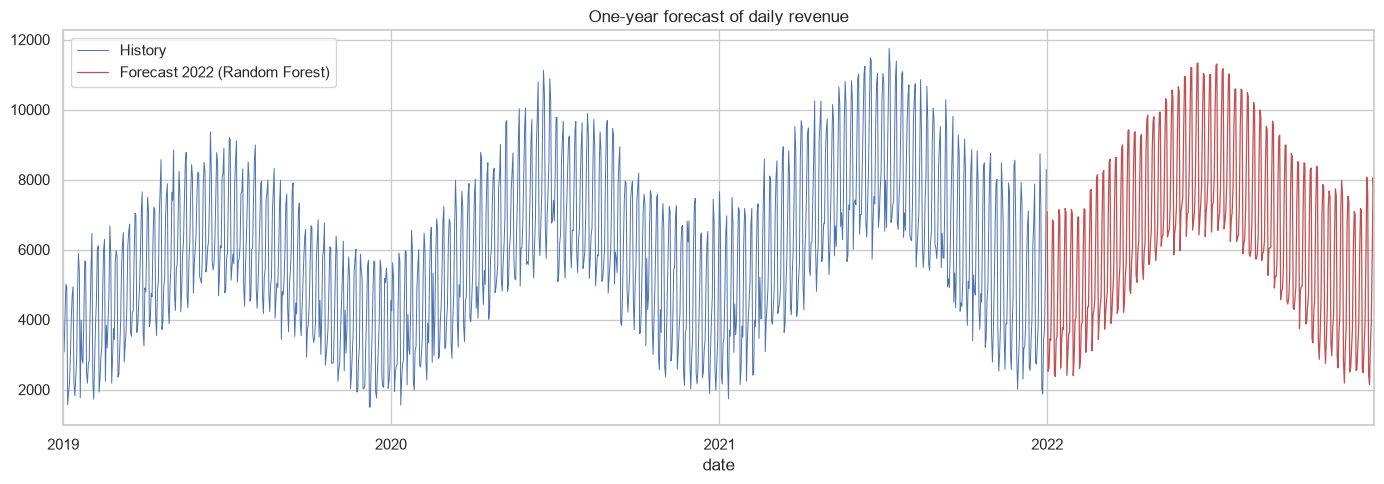

,2021 actual,2022 forecast
0,2398295.0,2384113.0


,forecast revenue
2022-01-01,140281.0
2022-02-01,143354.0
2022-03-01,187685.0
2022-04-01,219256.0
2022-05-01,242718.0
2022-06-01,258730.0
2022-07-01,268527.0
2022-08-01,234934.0
2022-09-01,205566.0
2022-10-01,179574.0


In [16]:
fm=copy.deepcopy(models[best]); fm.fit(X,y)
fidx=pd.date_range(ts.index.max()+pd.Timedelta(days=1),periods=365,freq="D")
fc=pd.Series(fm.predict(feats(fidx)),index=fidx)
plt.figure(figsize=(14,5)); y.plot(label="History",lw=.7); fc.plot(label=f"Forecast 2022 ({best})",color="r",lw=.9); plt.legend(); plt.title("One-year forecast of daily revenue"); save("10_forecast_next_year")
display(pd.DataFrame({"2021 actual":[y["2021"].sum()],"2022 forecast":[fc.sum()]}).round(0)); fc.resample("MS").sum().round(0).to_frame("forecast revenue")

**Interpretation.** The Random Forest retrained on all data forecasts about 2.38M revenue for 2022, with the same seasonal shape (peak June-August, trough January-February). This is nearly flat against 2021 (2.40M) even though past years grew about 12% per year: tree models cannot extrapolate the `year` feature beyond the training range, so the forecast reproduces the most recent level and seasonality without the growth trend. Treat it as a conservative, seasonality-only forecast.

## 4. Deep learning: LSTM (extra, from the grading rubric)
Daily revenue is scaled; windows of the last 28 days predict the next day. The model is trained on the first 24 months (training series). The final 12 months (test series) are generated recursively - each prediction is fed back as input, so no actual test values are seen - and compared with the real values using MAPE.

Train series: 2019-01-01 -> 2020-12-31 | test series: 2021-01-01 -> 2021-12-31


epochs run: 25 | best val loss 0.1054


LSTM (12-month recursive) MAPE: 26.93% | RMSE 2239.3


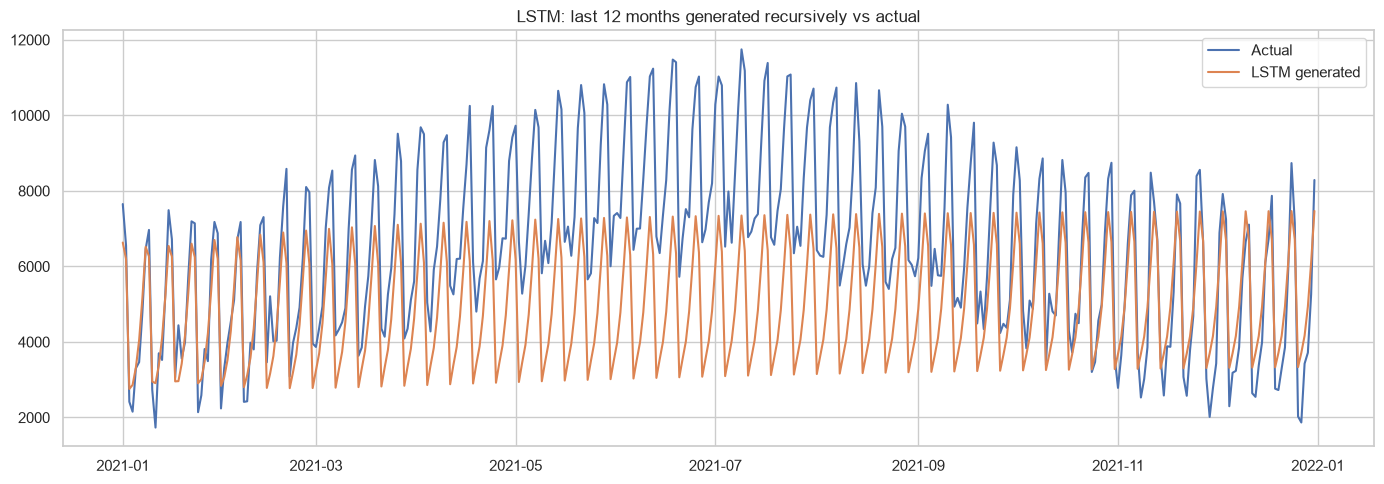

LSTM one-step-ahead MAPE on the same 12 months: 10.68% | RMSE 727.8


In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models as km
tf.random.set_seed(42); np.random.seed(42)
vals=y.values.astype("float32"); cut=len(vals)-365
mu,sd_=vals[:cut].mean(),vals[:cut].std(); sc=(vals-mu)/sd_
W=28
def win(a): return np.array([a[i:i+W] for i in range(len(a)-W)])[...,None], a[W:]
Xl,yl=win(sc[:cut]); print("Train series:",ts.index[0].date(),"->",ts.index[cut-1].date(),"| test series:",ts.index[cut].date(),"->",ts.index[-1].date())
def build():
    m=km.Sequential([layers.Input((W,1)),layers.LSTM(48),layers.Dense(1)]); m.compile("adam","mse"); return m
lstm=build(); h=lstm.fit(Xl,yl,epochs=40,batch_size=32,validation_split=.1,verbose=0,callbacks=[tf.keras.callbacks.EarlyStopping(patience=6,restore_best_weights=True)])
print("epochs run:",len(h.history["loss"]),"| best val loss %.4f"%min(h.history["val_loss"]))
def recursive(model,seed,n):
    buf=list(seed); out=[]
    for _ in range(n):
        p=float(model.predict(np.array(buf[-W:],dtype="float32")[None,:,None],verbose=0)[0,0]); out.append(p); buf.append(p)
    return np.array(out)
pt=recursive(lstm,sc[cut-W:cut],365)*sd_+mu; act=vals[cut:]
mape=100*np.mean(np.abs((act-pt)/act)); lr_=rmse(act,pt)
print("LSTM (12-month recursive) MAPE: %.2f%% | RMSE %.1f"%(mape,lr_))
plt.figure(figsize=(14,5)); plt.plot(ts.index[cut:],act,label="Actual"); plt.plot(ts.index[cut:],pt,label="LSTM generated"); plt.legend(); plt.title("LSTM: last 12 months generated recursively vs actual"); save("11_lstm_test")
Xt,yt=win(sc[cut-W:]); p1=lstm.predict(Xt,verbose=0).ravel()*sd_+mu; a1=yt*sd_+mu
mape1=100*np.mean(np.abs((a1-p1)/a1)); print("LSTM one-step-ahead MAPE on the same 12 months: %.2f%% | RMSE %.1f"%(mape1,rmse(a1,p1)))

**Interpretation.** All three files load cleanly: sales has 109,600 rows (100 items x 1,096 days, 2019-01-01 to 2021-12-31), items 100 rows, restaurants 6 rows. There are no missing values and no duplicate rows. About 79% of sales rows have `item_count = 0` (item not sold that day), and the non-zero counts are strongly right-skewed (2,595 of 23,484 non-zero rows exceed the IQR fence of 71, maximum 570). These are genuine high-demand days of popular items, not entry errors, so no rows were removed. The sales price equals the item cost for every row, so prices are constant per item. Six item names repeat across stores, so the merge uses item id, not name.0

### Final LSTM on the entire series: forecast the next three months

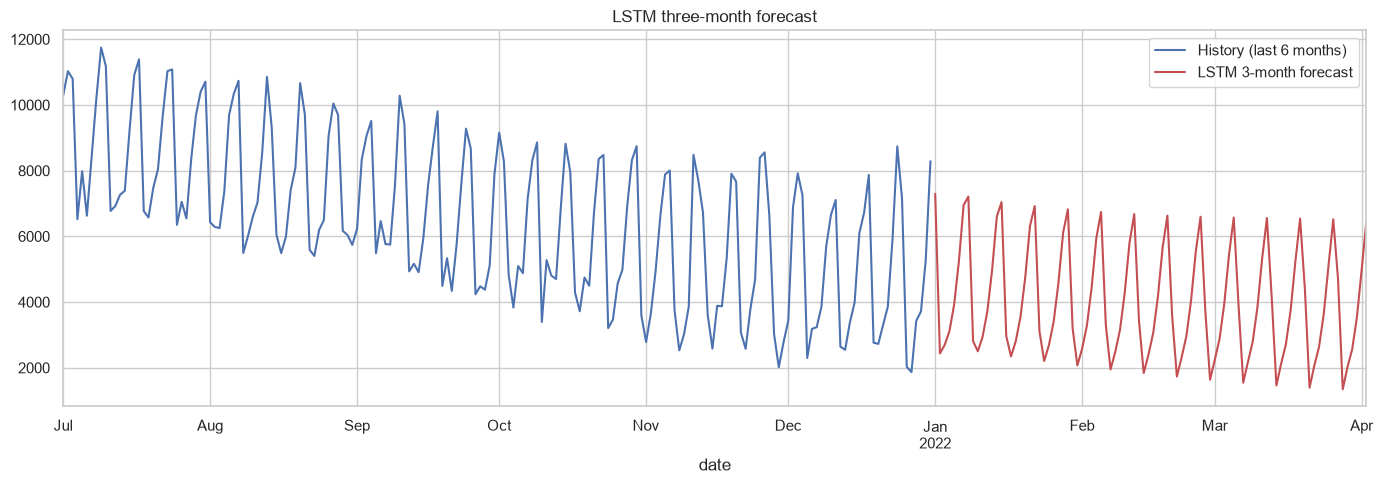

Forecast total Jan-Mar 2022: 367930 | Jan-Mar 2021 actual: 476023


,Model,RMSE,MAPE %
0,Random Forest,826.85,11.08
1,XGBoost,894.98,14.56
2,Seasonal naive (364d),967.80,11.81
3,Linear Regression,2234.61,40.57
4,LSTM recursive 12m,2239.32,26.93
5,LSTM one-step 12m,727.77,10.68


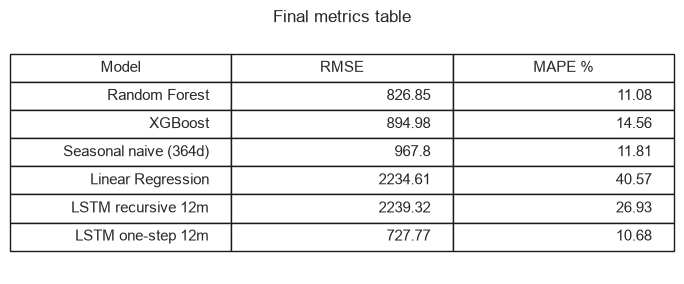

Notebook run time: 3.4 min


In [18]:
tf.random.set_seed(7)
m_all,s_all=vals.mean(),vals.std(); sc_all=(vals-m_all)/s_all
Xa,ya=win(sc_all)
lstm2=build(); lstm2.fit(Xa,ya,epochs=25,batch_size=32,verbose=0)
f3=recursive(lstm2,sc_all[-W:],92)*s_all+m_all
i3=pd.date_range(ts.index.max()+pd.Timedelta(days=1),periods=92,freq="D")
plt.figure(figsize=(14,5)); y["2021-07":].plot(label="History (last 6 months)"); pd.Series(f3,index=i3).plot(label="LSTM 3-month forecast",color="r"); plt.legend(); plt.title("LSTM three-month forecast"); save("12_lstm_forecast_3m")
print("Forecast total Jan-Mar 2022: %.0f | Jan-Mar 2021 actual: %.0f"%(f3.sum(),y["2021-01":"2021-03"].sum()))
all_res=pd.concat([rm[["Model","RMSE","MAPE %"]],pd.DataFrame([["LSTM recursive 12m",lr_,mape],["LSTM one-step 12m",rmse(a1,p1),mape1]],columns=["Model","RMSE","MAPE %"])]).reset_index(drop=True)
display(all_res.round(2))
fig,ax=plt.subplots(figsize=(7,3)); ax.axis("off"); t=ax.table(cellText=all_res.round(2).values,colLabels=list(all_res.columns),loc="center"); t.scale(1,1.6); ax.set_title("Final metrics table"); save("00_metrics_table")
all_res.round(3).to_csv("figures/metrics.csv",index=False)
print("Notebook run time: %.1f min"%((time.time()-T0)/60))

## 5. Conclusions
* Revenue is strongly seasonal (Q2/Q3 about 50% above Q1/Q4; June is the peak) and weekly (Thursday-Saturday are the best days, Sunday and Monday the weakest), with about 12-14% yearly growth.
* Bob's Diner generates more than 99% of revenue; the other five restaurants sell about 1-2 units a day, so any decision about demand is effectively a Bob's Diner decision (this is also a data-quality flag worth raising with the data owner).
* Strawberry Smoothy is the top item. The top store is also the most profitable per day.
* Model comparison (last six months): Random Forest RMSE about 827 < XGBoost about 895 < Linear Regression about 2,235. The Random Forest is used for the 2022 forecast (about 2.38M, seasonality-only because tree models cannot extrapolate growth).
* LSTM: one-step MAPE about 11%, recursive 12-month MAPE about 27%; the three-month LSTM forecast (Jan-Mar 2022) is in the last chart, and its total is below the Jan-Mar 2021 actual because the recursive LSTM damps the seasonal level, so it should be viewed with caution.